In [10]:
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns
import numpy as np 
import warnings
warnings.filterwarnings('ignore')

In [11]:
df=pd.read_csv("heart (1).csv")

In [12]:
df

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0
...,...,...,...,...,...,...,...,...,...,...,...,...
913,45,M,TA,110,264,0,Normal,132,N,1.2,Flat,1
914,68,M,ASY,144,193,1,Normal,141,N,3.4,Flat,1
915,57,M,ASY,130,131,0,Normal,115,Y,1.2,Flat,1
916,57,F,ATA,130,236,0,LVH,174,N,0.0,Flat,1


In [13]:
# In my condition no any duplicated values
df.duplicated().sum()

np.int64(0)

In [14]:
df.value_counts('ChestPainType')

ChestPainType
ASY    496
NAP    203
ATA    173
TA      46
Name: count, dtype: int64

In [15]:
df.value_counts('RestingECG')

RestingECG
Normal    552
LVH       188
ST        178
Name: count, dtype: int64

In [16]:
df.value_counts('ST_Slope')

ST_Slope
Flat    460
Up      395
Down     63
Name: count, dtype: int64

In [17]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Age,918.0,53.510893,9.432617,28.0,47.00,54.0,60.0,77.0
RestingBP,918.0,132.396514,18.514154,0.0,120.00,130.0,140.0,200.0
Cholesterol,918.0,198.799564,109.384145,0.0,173.25,223.0,267.0,603.0
FastingBS,918.0,0.233115,0.423046,0.0,0.00,0.0,0.0,1.0
MaxHR,918.0,136.809368,25.460334,60.0,120.00,138.0,156.0,202.0
Oldpeak,918.0,0.887364,1.066570,-2.6,0.00,0.6,1.5,6.2
HeartDisease,918.0,0.553377,0.497414,0.0,0.00,1.0,1.0,1.0


In [18]:
df.columns

Index(['Age', 'Sex', 'ChestPainType', 'RestingBP', 'Cholesterol', 'FastingBS',
       'RestingECG', 'MaxHR', 'ExerciseAngina', 'Oldpeak', 'ST_Slope',
       'HeartDisease'],
      dtype='object')

In [19]:
df.isnull().sum()

Age               0
Sex               0
ChestPainType     0
RestingBP         0
Cholesterol       0
FastingBS         0
RestingECG        0
MaxHR             0
ExerciseAngina    0
Oldpeak           0
ST_Slope          0
HeartDisease      0
dtype: int64

In [20]:
df.dtypes

Age                 int64
Sex                object
ChestPainType      object
RestingBP           int64
Cholesterol         int64
FastingBS           int64
RestingECG         object
MaxHR               int64
ExerciseAngina     object
Oldpeak           float64
ST_Slope           object
HeartDisease        int64
dtype: object

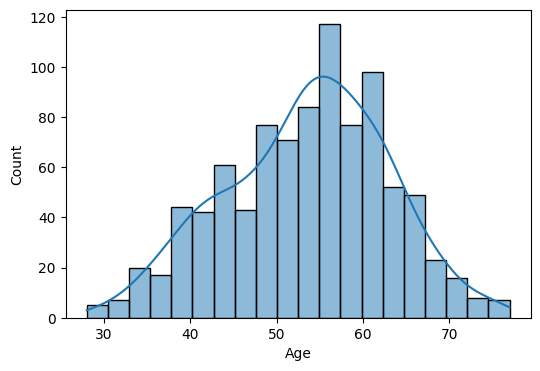

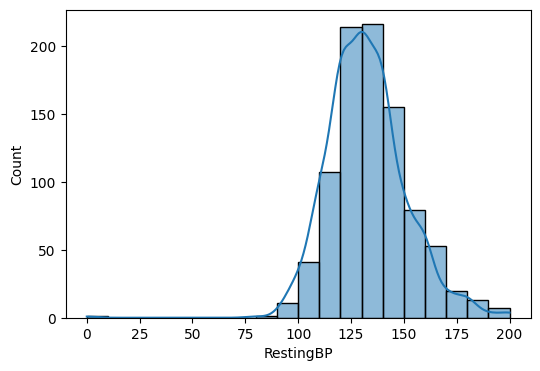

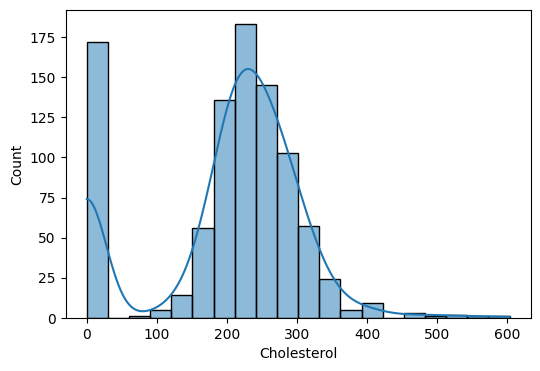

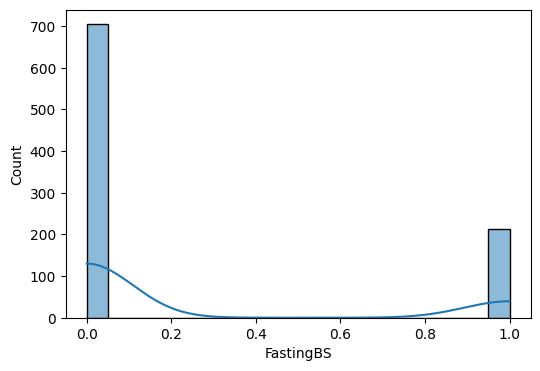

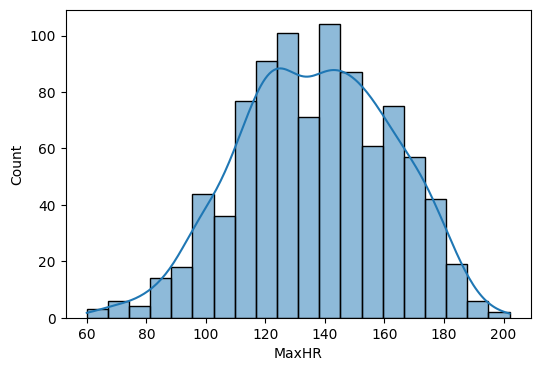

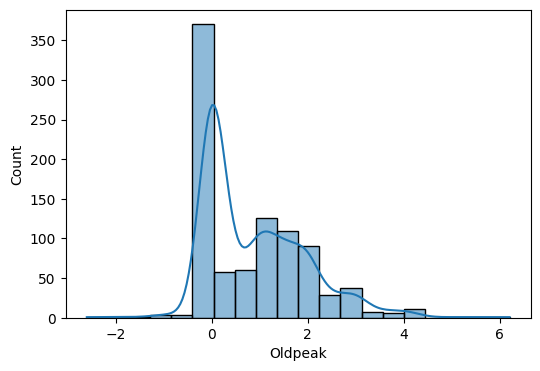

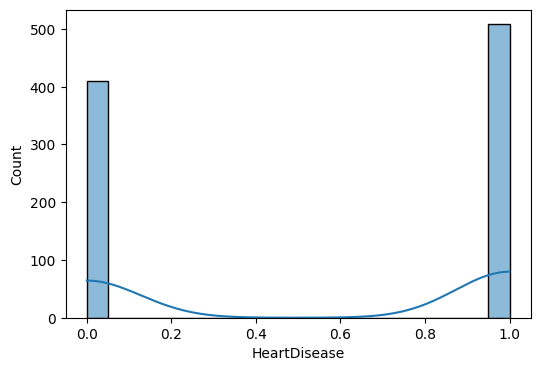

In [21]:
int_columns=['Age','RestingBP','Cholesterol','FastingBS','MaxHR','Oldpeak','HeartDisease']
for cols in int_columns: 
    plt.figure(figsize=(6,4))
    sns.histplot(df[cols],bins=20,kde=True,)

In [22]:
# Cholesterol and RestingBP=0 is not posible in human

In [23]:
# Check how many 0 value in RestingBP Row
(df["RestingBP"]==0).sum()
# df["RestingBP"].value_counts()

np.int64(1)

In [24]:
# Delete RestingBP=0 from row because row is >5% of dataset 
df=df[df["RestingBP"]!=0]

In [25]:
# Re-check ,all right
(df["RestingBP"]==0).sum()

np.int64(0)

In [26]:
(df['Cholesterol']==0).sum()

np.int64(171)

In [27]:
df["Cholesterol"].value_counts()

Cholesterol
0      171
254     11
220     10
223     10
204      9
      ... 
353      1
278      1
157      1
176      1
131      1
Name: count, Length: 222, dtype: int64

In [28]:
# now for Cholestrol 
# I will do that later for preventing from data leakage.

In [29]:
df.dtypes

Age                 int64
Sex                object
ChestPainType      object
RestingBP           int64
Cholesterol         int64
FastingBS           int64
RestingECG         object
MaxHR               int64
ExerciseAngina     object
Oldpeak           float64
ST_Slope           object
HeartDisease        int64
dtype: object

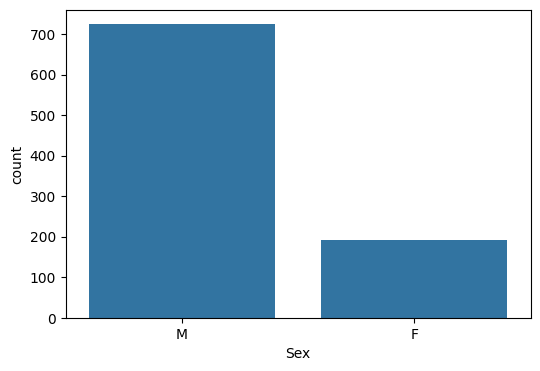

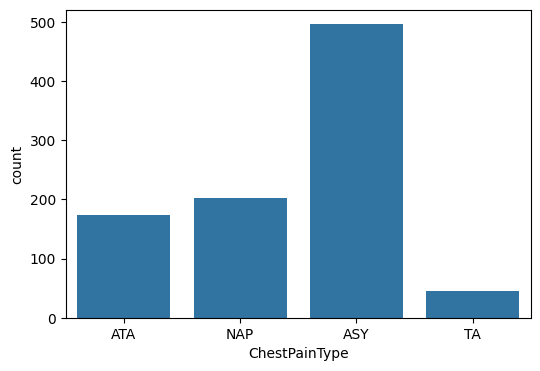

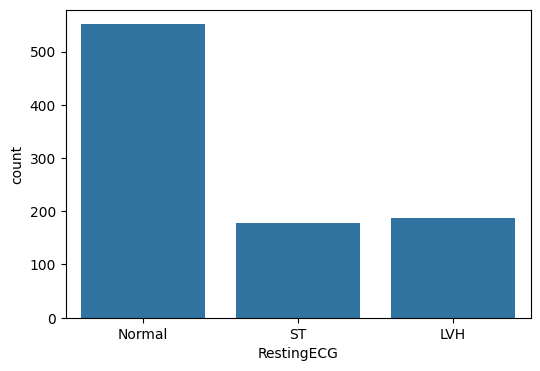

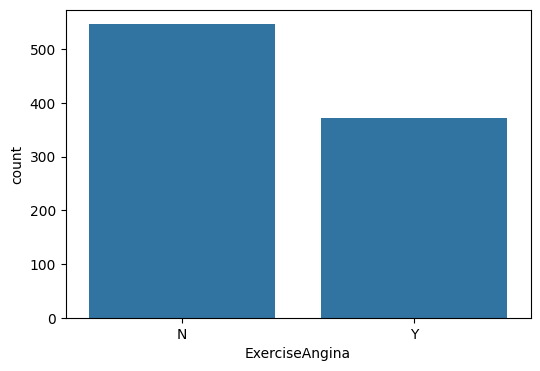

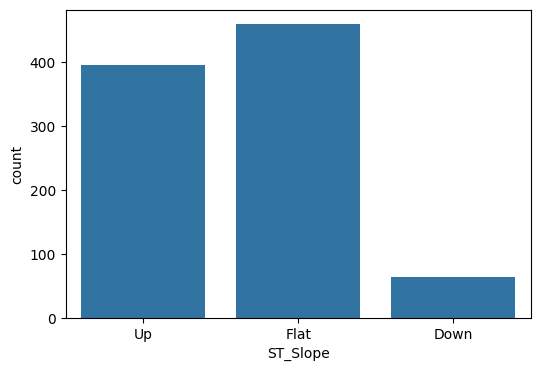

In [30]:
obj_columns=['Sex','ChestPainType','RestingECG','ExerciseAngina','ST_Slope']
for col in obj_columns:
    plt.figure(figsize=(6,4))
    sns.countplot(x=df[col])

In [31]:
df.columns

Index(['Age', 'Sex', 'ChestPainType', 'RestingBP', 'Cholesterol', 'FastingBS',
       'RestingECG', 'MaxHR', 'ExerciseAngina', 'Oldpeak', 'ST_Slope',
       'HeartDisease'],
      dtype='object')

In [32]:
df.value_counts('Sex')

Sex
M    724
F    193
Name: count, dtype: int64

In [33]:
df.value_counts('FastingBS')

FastingBS
0    703
1    214
Name: count, dtype: int64

In [34]:
df.value_counts('ExerciseAngina')

ExerciseAngina
N    546
Y    371
Name: count, dtype: int64

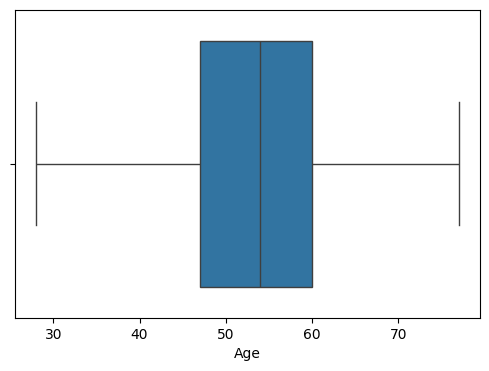

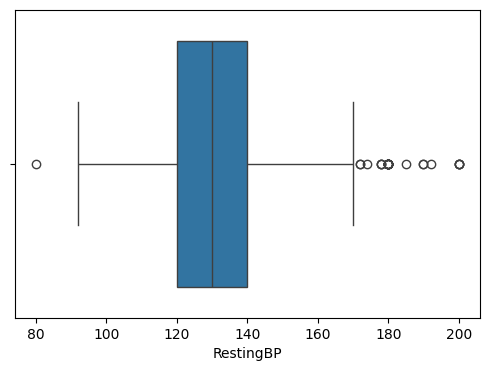

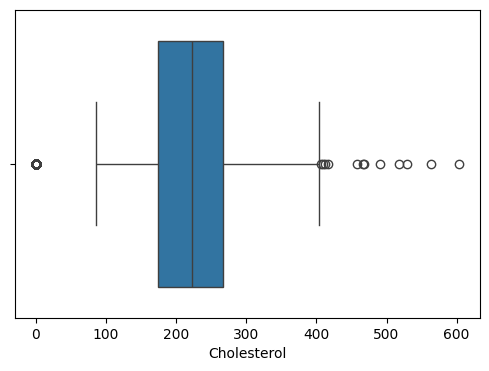

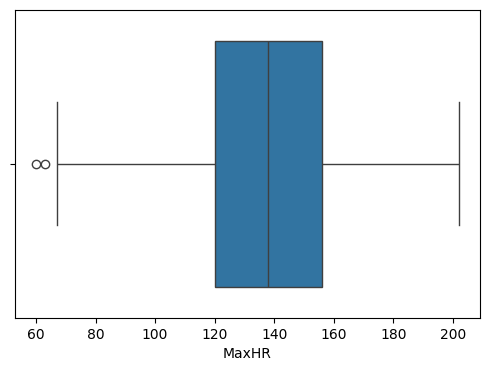

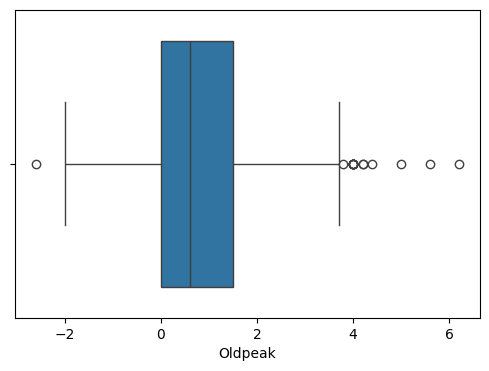

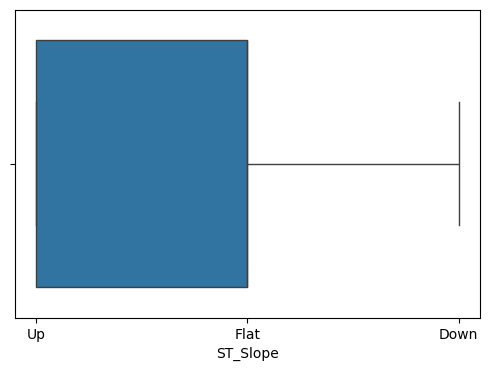

In [35]:
all_columns=['Age', 'RestingBP', 'Cholesterol',
        'MaxHR', 'Oldpeak', 'ST_Slope']
for all_cols in all_columns: 
    plt.figure(figsize=(6,4))
    sns.boxplot(x=df[all_cols])

In [36]:
df

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0
...,...,...,...,...,...,...,...,...,...,...,...,...
913,45,M,TA,110,264,0,Normal,132,N,1.2,Flat,1
914,68,M,ASY,144,193,1,Normal,141,N,3.4,Flat,1
915,57,M,ASY,130,131,0,Normal,115,Y,1.2,Flat,1
916,57,F,ATA,130,236,0,LVH,174,N,0.0,Flat,1


<Axes: xlabel='HeartDisease'>

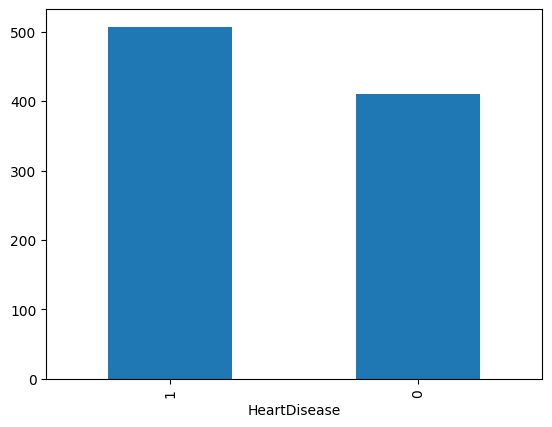

In [37]:
df['HeartDisease'].value_counts().plot(kind="bar")

In [38]:
df.isnull().sum()

Age               0
Sex               0
ChestPainType     0
RestingBP         0
Cholesterol       0
FastingBS         0
RestingECG        0
MaxHR             0
ExerciseAngina    0
Oldpeak           0
ST_Slope          0
HeartDisease      0
dtype: int64

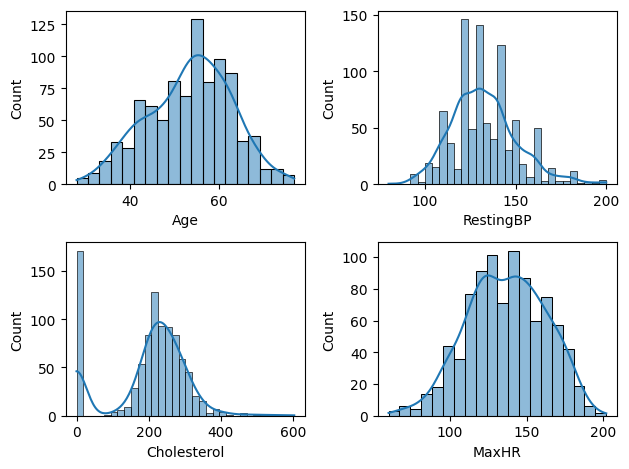

In [39]:
def plotting(var,num): 
    plt.subplot(2,2,num)
    sns.histplot(df[var],kde=True)
    
plotting('Age',1)
plotting('RestingBP',2) 
plotting('Cholesterol',3) 
plotting('MaxHR',4) 
plt.tight_layout()

In [40]:
df['Cholesterol'].value_counts()

Cholesterol
0      171
254     11
220     10
223     10
204      9
      ... 
353      1
278      1
157      1
176      1
131      1
Name: count, Length: 222, dtype: int64

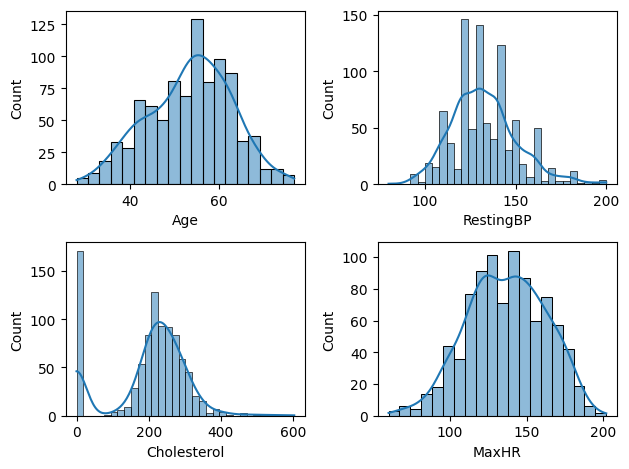

In [41]:
def plotting(var,num): 
    plt.subplot(2,2,num)
    sns.histplot(df[var],kde=True)
    
plotting('Age',1)
plotting('RestingBP',2) 
plotting('Cholesterol',3) 
plotting('MaxHR',4) 
plt.tight_layout()


<Axes: xlabel='Sex', ylabel='count'>

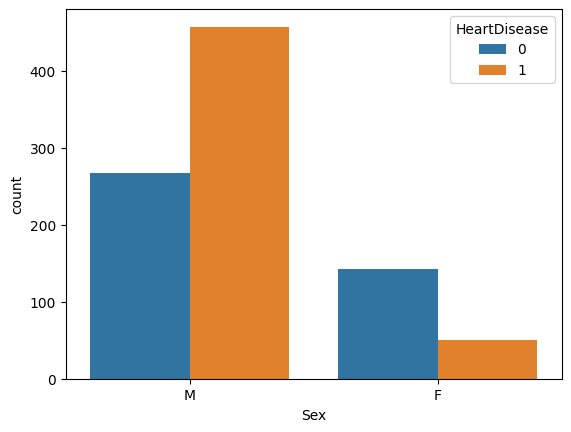

In [42]:
sns.countplot(x=df['Sex'],hue=df['HeartDisease'])

<Axes: xlabel='ChestPainType', ylabel='count'>

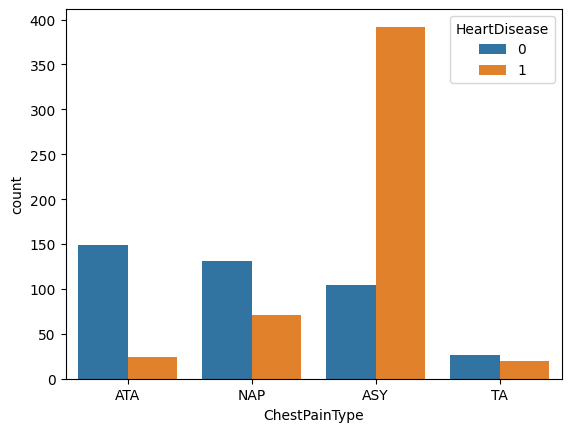

In [43]:
sns.countplot(x=df['ChestPainType'],hue=df['HeartDisease'])

<Axes: xlabel='FastingBS', ylabel='count'>

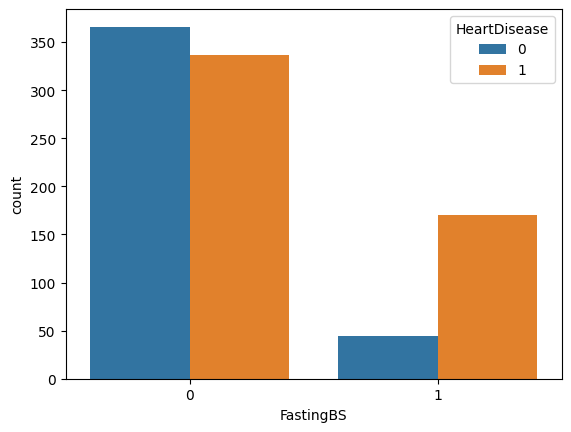

In [44]:
sns.countplot(x=df['FastingBS'],hue=df['HeartDisease'])

<Axes: xlabel='HeartDisease', ylabel='Cholesterol'>

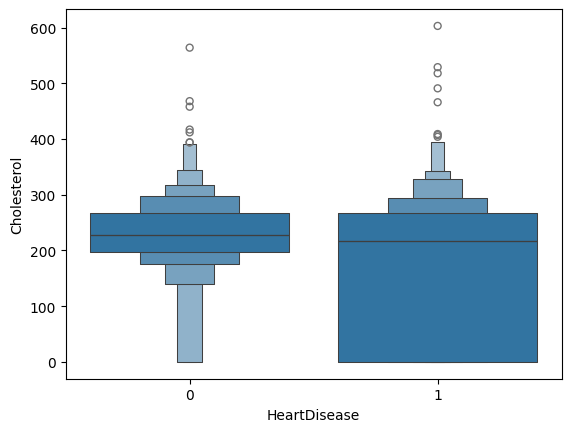

In [45]:
sns.boxenplot(x='HeartDisease',y='Cholesterol',data=df)

<Axes: xlabel='HeartDisease', ylabel='Age'>

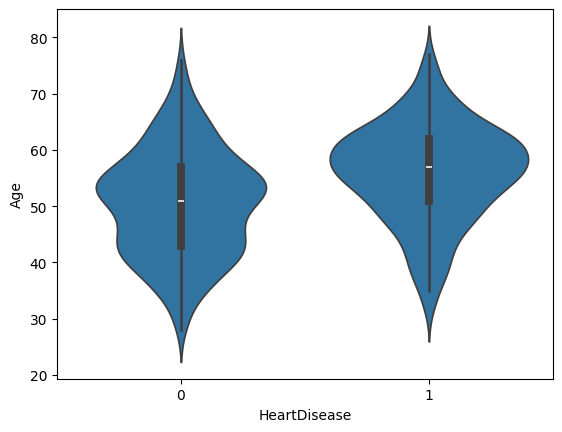

In [46]:
sns.violinplot(x='HeartDisease',y='Age',data=df)

<Axes: >

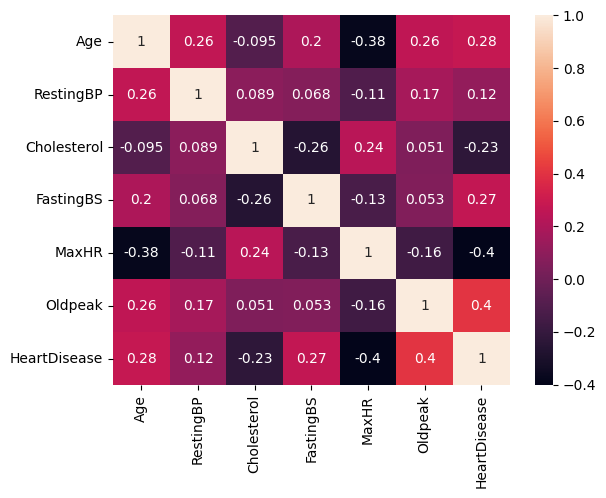

In [47]:
sns.heatmap(df.corr(numeric_only=True),annot=True)

### Data preprocessing

In [48]:
df["Cholesterol"] = df["Cholesterol"].replace(0, np.nan)

In [49]:
print(df[["RestingBP", "Cholesterol"]].isnull().sum())

RestingBP        0
Cholesterol    171
dtype: int64


In [50]:
X=df.drop("HeartDisease",axis=1)
y=df["HeartDisease"]

In [51]:
print(X.shape)
print(y.shape)

(917, 11)
(917,)


In [52]:
# import numpy as np
# import pandas as pd

# from sklearn.model_selection import (
#     train_test_split,
#     StratifiedKFold,
#     cross_validate,
#     GridSearchCV
# )

# from sklearn.pipeline import Pipeline

# from sklearn.preprocessing import OneHotEncoder, StandardScaler

# from sklearn.impute import SimpleImputer

# from sklearn.linear_model import LogisticRegression
# from sklearn.ensemble import RandomForestClassifier
# from sklearn.svm import SVC

# from sklearn.metrics import (
#     accuracy_score,
#     precision_score,
#     recall_score,
#     f1_score,
#     roc_auc_score,
#     classification_report,
#     confusion_matrix
# )

# from xgboost import XGBClassifier

In [53]:
from sklearn.model_selection import (train_test_split, 
                                    GridSearchCV, 
                                    cross_validate,
                                    StratifiedKFold)
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)
#if our classes are imbalance then we can use stratify=y because ensures that the class 
#distribution of the target variable y is maintained in both training and testing datasets.

In [54]:
categorical_cols = [
    "Sex",
    "ChestPainType",
    "RestingECG",
    "ExerciseAngina",
    "ST_Slope"
]

In [55]:
numerical_cols = [
    "Age",
    "RestingBP",
    "Cholesterol",
    "FastingBS",
    "MaxHR",
    "Oldpeak"
]

In [56]:
# pip install pipeline

In [57]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler,OneHotEncoder

In [58]:
# Preprocessing for LogisticRegression and SVM
from sklearn.compose import ColumnTransformer, make_column_transformer

numeric_scaled = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor_scaled = ColumnTransformer([
    ("num", numeric_scaled, numerical_cols),
    ("cat", categorical, categorical_cols)
])

In [59]:
# Preprocessing for RandomForest and XGboost

numeric_tree = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

preprocessor_tree = ColumnTransformer([
    ("num", numeric_tree, numerical_cols),
    ("cat", categorical, categorical_cols)
])

In [60]:
# Models preparation
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from xgboost import XGBClassifier
# LogisticRegression Model
logistic_model = Pipeline([
    ("preprocessor", preprocessor_scaled),
    ("model", LogisticRegression(max_iter=1000))
])

# RandomForestClassifier Model
rf_model = Pipeline([
    ("preprocessor", preprocessor_tree),
    ("model", RandomForestClassifier(
        random_state=42
    ))
])

# Support_Vector_Machine Model
svm_model = Pipeline([
    ("preprocessor", preprocessor_scaled),
    ("model", SVC(
        probability=True,
        random_state=42
    ))
])

# XGBoost Model
xgb_model = Pipeline([
    ("preprocessor", preprocessor_tree),
    ("model", XGBClassifier(
        random_state=42,
        eval_metric="logloss"
    ))
])


models = {
    "Logistic Regression": logistic_model,
    "Random Forest": rf_model,
    "SVM": svm_model,
    "XGBoost": xgb_model
}

In [61]:
# Cross Validation

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc"
}

In [62]:
# Model Comparision
results = []
for name, model in models.items():
    scores = cross_validate(model,X_train,y_train,cv=cv,scoring=scoring,n_jobs=-1)

    results.append({
        "Model": name,
        "Accuracy": scores["test_accuracy"].mean(),
        "Precision": scores["test_precision"].mean(),
        "Recall": scores["test_recall"].mean(),
        "F1": scores["test_f1"].mean(),
        "ROC-AUC": scores["test_roc_auc"].mean()
    })

results_df = pd.DataFrame(results)
print('Models ')
print(
    results_df.sort_values(
        by="ROC-AUC",
        ascending=False
    )
)


Models 
                 Model  Accuracy  Precision    Recall        F1   ROC-AUC
1        Random Forest  0.858131   0.860543  0.891358  0.874615  0.927222
3              XGBoost  0.858121   0.859700  0.891358  0.874117  0.921313
2                  SVM  0.859538   0.858348  0.898765  0.876949  0.916750
0  Logistic Regression  0.841776   0.852841  0.869136  0.859023  0.916122


In [63]:
# Random Forest Hyperparameter Tuning

rf_param_grid = {"model__n_estimators": [100,200,300],
                 "model__max_depth": [None,5,10,20],
                 "model__min_samples_split": [2,5,10],
                 "model__min_samples_leaf": [1,2,4],
                 "model__max_features": ["sqrt","log2"]
                }
rf_grid = GridSearchCV(estimator=rf_model,param_grid=rf_param_grid,cv=cv,scoring="roc_auc",n_jobs=-1,
                       verbose=1
                      )
rf_grid.fit(X_train, y_train)

Fitting 5 folds for each of 216 candidates, totalling 1080 fits


,estimator,Pipeline(step...m_state=42))])
,param_grid,"{'model__max_depth': [None, 5, ...], 'model__max_features': ['sqrt', 'log2'], 'model__min_samples_leaf': [1, 2, ...], 'model__min_samples_split': [2, 5, ...], ...}"
,scoring,'roc_auc'
,n_jobs,-1
,refit,True
,cv,StratifiedKFo... shuffle=True)
,verbose,1
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,transformers,"[('num', ...), ('cat', ...)]"


In [64]:
# Best Parameters

print("\nBEST PARAMETERS")
print(rf_grid.best_params_)
print("\nBEST CV ROC-AUC")
print(rf_grid.best_score_)


BEST PARAMETERS
{'model__max_depth': None, 'model__max_features': 'sqrt', 'model__min_samples_leaf': 2, 'model__min_samples_split': 5, 'model__n_estimators': 300}

BEST CV ROC-AUC
0.9311893867449422


In [65]:
# Final Testing Evalution

best_rf = rf_grid.best_estimator_
y_pred = best_rf.predict(X_test)
y_prob = best_rf.predict_proba(X_test)[:, 1]

In [66]:
# Metrics
from sklearn.metrics import (accuracy_score,auc,accuracy_score,precision_score,recall_score,
f1_score,roc_auc_score, )

accuracy = accuracy_score(y_test,y_pred)
precision = precision_score(y_test,y_pred)
recall = recall_score(y_test,y_pred)

f1 = f1_score(y_test,y_pred)

roc_auc = roc_auc_score(y_test,y_prob)


print("\n Final Test Results")

print("Accuracy :", accuracy)
print("Precision:", precision)
print("Recall   :", recall)
print("F1 Score :", f1)
print("ROC-AUC  :", roc_auc)


 Final Test Results
Accuracy : 0.8858695652173914
Precision: 0.8857142857142857
Recall   : 0.9117647058823529
F1 Score : 0.8985507246376812
ROC-AUC  : 0.9349593495934959


In [70]:
# Classification Report
from sklearn.metrics import classification_report,confusion_matrix

print("\n Classification Report")

print(
    classification_report(
        y_test,
        y_pred
    )
)


 Classification Report
              precision    recall  f1-score   support

           0       0.89      0.85      0.87        82
           1       0.89      0.91      0.90       102

    accuracy                           0.89       184
   macro avg       0.89      0.88      0.88       184
weighted avg       0.89      0.89      0.89       184



In [71]:
# Confusion Matrix


print("\n Confusion Matrix")

print(
    confusion_matrix(
        y_test,
        y_pred
    )
)


 Confusion Matrix
[[70 12]
 [ 9 93]]


In [72]:
import joblib
joblib.dump(best_rf, "heart_model.joblib", compress=3)
print("Model saved!")

Model saved!


In [73]:
import sklearn; print(sklearn.__version__)

1.7.2


In [74]:
import sklearn
import sys

print("Scikit-learn version:", sklearn.__version__)
print("Python executable:", sys.executable)

Scikit-learn version: 1.7.2
Python executable: c:\Users\sawsu\OneDrive\Desktop\HeartDiseaseApp\.heart\Scripts\python.exe


In [75]:
import sys
print(sys.version)
print(sys.executable)

3.10.2 (tags/v3.10.2:a58ebcc, Jan 17 2022, 14:12:15) [MSC v.1929 64 bit (AMD64)]
c:\Users\sawsu\OneDrive\Desktop\HeartDiseaseApp\.heart\Scripts\python.exe
